# Ciudad Incremental · Análisis de transporte
### ¿Dónde reubicar a las familias que viven en zonas de alto riesgo de Medellín, sin alejarlas de la ciudad?

---

**La idea en pocas palabras**

En Medellín hay familias viviendo en laderas o junto a quebradas donde el riesgo de deslizamiento o inundación es tan alto que ninguna obra lo resuelve: tienen que mudarse. *Ciudad Incremental* propone preparar primero un terreno seguro, con servicios y vías, y llevar allí a esas familias, con una vivienda que puedan ir ampliando con el tiempo.

Este notebook ayuda a responder **dónde** debería estar ese terreno, mirando algo que suele olvidarse: **que desde la nueva casa se pueda llegar caminando al metro, al bus, al centro de salud y al colegio**. Muchos reasentamientos fracasan porque las familias quedan lejos de todo.

**Lo que NO hace este análisis:** no busca el mejor terreno de toda la ciudad. Busca, para cada barrio en riesgo, un terreno **seguro y cercano** donde las familias queden igual o mejor conectadas que hoy.

---

**Cómo leer este notebook**

Cada paso tiene una explicación (como esta) y debajo el código que hace el cálculo. **No necesitas entender el código**: basta con ejecutar las celdas en orden (botón ▶ o `Shift + Enter`) y leer los textos y los mapas.

| Paso | Qué se hace |
|---|---|
| 0 | Descargar los mapas oficiales de la Alcaldía |
| 1 | Delimitar Medellín |
| 2 | Leer el relieve (qué tan empinado es cada lugar) |
| 3 | Descargar las calles y calcular cuánto se tarda una persona en recorrer cada una |
| 4 | Ubicar las estaciones, paraderos, centros de salud y colegios |
| 5 | Calcular cuántos minutos hay caminando desde cada esquina hasta cada uno |
| 6 | Dividir la ciudad en hexágonos para comparar zonas |
| 7 | Encontrar los barrios en riesgo |
| 8 | Descartar el terreno donde no se puede construir |
| 9 y 10 | Calificar cada terreno posible |
| 11 | Elegir los mejores sitios para cada barrio |
| 12 | Guardar mapas y resultados |
| 13 | Comprobar que el resultado no depende de una decisión arbitraria |

**Antes de empezar:** pon tu modelo digital de elevaciones en `datos/output_be.tif`. Lo demás se descarga solo (la primera vez tarda varios minutos).

In [1]:
# Librerías que usa el análisis
import warnings, unicodedata, io, time
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import osmnx as ox
import rasterio
import requests
from rasterio.mask import mask as rio_mask
from rasterio.warp import calculate_default_transform, reproject, Resampling
from shapely.geometry import Polygon, Point, LineString
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
ox.settings.use_cache = True
ox.settings.log_console = False
pd.set_option("display.max_columns", 50)

# Servidores públicos de OpenStreetMap (Overpass). Si uno está saturado, se prueba el siguiente.
SERVIDORES_OSM = ["https://overpass-api.de/api",
                  "https://overpass.kumi.systems/api",
                  "https://overpass.private.coffee/api"]

def descargar_osm(funcion, *args, rondas=3, **kwargs):
    # Ejecuta una descarga de OpenStreetMap; si falla, prueba otros servidores y espera antes de reintentar
    ultimo = None
    for ronda in range(rondas):
        for url in SERVIDORES_OSM:
            ox.settings.overpass_url = url
            try:
                return funcion(*args, **kwargs)
            except ox._errors.InsufficientResponseError:
                raise                                   # el servidor respondió, pero no hay datos
            except Exception as e:
                ultimo = e
                print(f"  · {url.split('/')[2]} no respondió ({type(e).__name__}); probando otro servidor…")
        espera = 30 * (ronda + 1)
        if ronda < rondas - 1:
            print(f"  · Todos los servidores están ocupados. Esperando {espera} s antes de reintentar…")
            time.sleep(espera)
    raise RuntimeError("OpenStreetMap no respondió después de varios intentos. "
                       "Espera unos minutos y vuelve a ejecutar esta celda.") from ultimo

def norm(s):
    # Pasa un texto a minúsculas y sin tildes, para comparar nombres sin errores
    return unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().strip().lower()

print("Listo. osmnx", ox.__version__, "| geopandas", gpd.__version__)

Listo. osmnx 2.1.1 | geopandas 1.1.4


## Parámetros: las reglas del análisis

Aquí están **todas las reglas y números** que usa el análisis, en un solo lugar: cuántos minutos se consideran aceptables, qué tan empinado puede ser un terreno, cuánto pesa cada criterio, etc.

Si el equipo decide cambiar una regla (por ejemplo, exigir que el metro quede a 15 minutos en vez de 20), **se cambia solo aquí** y se vuelve a ejecutar todo.

> Estos valores son **una propuesta para discutir**, no una norma. El paso 13 revisa si los resultados cambian mucho cuando se modifican.

In [2]:
# ===================== CARPETAS Y ARCHIVOS =====================
LUGAR = "Medellín, Antioquia, Colombia"
DIR_DATOS = Path("datos"); DIR_POT = DIR_DATOS / "pot"; DIR_CACHE = DIR_DATOS / "cache"
DIR_SALIDA = Path("resultados")
for d in (DIR_DATOS, DIR_POT, DIR_CACHE, DIR_SALIDA):
    d.mkdir(parents=True, exist_ok=True)

RUTA_DEM = DIR_DATOS / "output_be.tif"     # modelo digital de elevaciones (lo pones tú)

# ===================== MAPAS OFICIALES DE LA ALCALDÍA =====================
# Se descargan solos en el paso 0 (POT Acuerdo 48 de 2014).
DESCARGAR_DATOS = True
_B = "https://www.medellin.gov.co/servidormapas/rest/services"
_SP = f"{_B}/ordenamiento_ter/VM_POT48_Suelo_Proteccion/MapServer"
CAPAS_REMOTAS = {
    "amenaza_movimientos_masa":      f"{_SP}/4",
    "amenaza_inundacion":            f"{_SP}/3",
    "amenaza_avenidas_torrenciales": f"{_SP}/2",
    "riesgo_movimientos_masa":       f"{_SP}/16",
    "riesgo_inundaciones":           f"{_SP}/15",
    "riesgo_avenidas_torrenciales":  f"{_SP}/5",
    "areas_protegidas":              f"{_SP}/6",
    "retiros_rios_quebradas":        f"{_SP}/7",
    "retiro_humedales":              f"{_SP}/8",
    "humedales":                     f"{_SP}/9",
    "tratamientos_urbanisticos":     f"{_B}/ordenamiento_ter/VM_22_Tratamientos_Urbanos/MapServer/0",
    "estaciones_sitva":              f"{_B}/transporte/VC_Infraest_Gestion_Transporte/MapServer/11",
    "paradas_tpc":                   f"{_B}/transporte/VC_Infraest_Gestion_Transporte/MapServer/0",
}
def ruta_capa(nombre):
    return DIR_POT / f"{nombre}.geojson"

# ===================== BARRIOS EN RIESGO (paso 7) =====================
# Zonas de ALTO RIESGO NO MITIGABLE: donde la norma obliga a reasentar.
CAPAS_RIESGO = [
    {"ruta": ruta_capa(n), "columna": "descripcion", "palabras": ["alto riesgo no mitigable"]}
    for n in ["riesgo_movimientos_masa", "riesgo_inundaciones", "riesgo_avenidas_torrenciales"]
]
RADIO_RIESGO_M = 100          # se incluye lo que está a 100 m o menos de esas zonas
# Mejoramiento Integral: barrios de origen informal según el POT. Poner None para no usarlo.
CAPA_MEJORAMIENTO = {"ruta": ruta_capa("tratamientos_urbanisticos"), "columna": "tratamiento",
                     "palabras": ["mejoramiento integral"]}

# ===================== TERRENO DONDE SE PUEDE CONSTRUIR (paso 8) =====================
CAPAS_AMENAZA = [
    {"nombre": "Movimientos en masa", "ruta": ruta_capa("amenaza_movimientos_masa"),
     "columna": "grado_amenaza", "valores_altos": ["Alta"]},
    {"nombre": "Inundación", "ruta": ruta_capa("amenaza_inundacion"),
     "columna": "grado_amenaza", "valores_altos": ["Alta"]},
    {"nombre": "Avenidas torrenciales", "ruta": ruta_capa("amenaza_avenidas_torrenciales"),
     "columna": "grado_amenaza", "valores_altos": ["Alta"]},
]
CAPAS_SUELO_APTO = [   # renovación, desarrollo y mejoramiento integral
    {"ruta": ruta_capa("tratamientos_urbanisticos"), "columna": "tratamiento",
     "palabras": ["renovacion", "desarrollo", "mejoramiento integral"]},
]
CAPAS_PROTECCION = [ruta_capa(n) for n in ["areas_protegidas", "retiros_rios_quebradas",
                                            "retiro_humedales", "humedales"]]

# ===================== TRANSPORTE =====================
RUTA_ESTACIONES = ruta_capa("estaciones_sitva")
ESTADOS_EXISTENTES = {"1", "existente"}    # solo estaciones que ya funcionan
RUTA_PARADEROS = ruta_capa("paradas_tpc")

# ===================== MEDIDAS Y CAMINATA =====================
CRS_PROY = "EPSG:9377"        # sistema de coordenadas en metros (el mismo del POT)
BUFFER_M = 1500               # margen alrededor de Medellín
RADIO_HEX_M = 100             # tamaño del hexágono (≈ 2,6 hectáreas)
RES_PENDIENTE_M = 30          # tamaño del píxel de pendiente
V_FUERA_RED_KMH = 3.0         # velocidad caminando por terreno sin calle
FACTOR_ESCALERAS = 0.7        # en escaleras se camina al 70 %
PENDIENTE_MAX_TRAMO = 1.0     # pendiente máxima creíble de un tramo (100 %)
LONG_MIN_PENDIENTE_M = 10     # tramos más cortos se toman como planos
CORTE_MIN = 120               # no se buscan destinos a más de 120 min caminando

# ===================== FILTROS (paso 8) =====================
FRAC_AMENAZA_MAX = 0.10       # máximo 10 % del hexágono en amenaza alta
PENDIENTE_MAX_PCT = 30        # pendiente media máxima
DIST_RED_MAX_M = 800          # distancia máxima a un camino existente

# ===================== EL MÍNIMO DEL DÍA DE LA MUDANZA =====================
PISO_PARADERO_MIN = 10        # paradero de bus a 10 min o menos caminando
PISO_MASIVO_MIN = 20          # metro, metrocable, tranvía o Metroplús a 20 min o menos

# ===================== COSTO DE LAS OBRAS (C1) =====================
# Unidades relativas: 1 = un metro de vía en terreno plano. Hay que calibrarlas con costos reales.
COSTOS = {
    "via_m": 1.0,             # por metro de vía o sendero hasta la red
    "factor_pendiente": 2.0,  # la vía cuesta más en ladera
    "paradero_o_ruta": 150,   # paradero nuevo o ajuste de ruta
    "peatonal_por_min": 40,   # escaleras, andenes, cubiertas: por minuto de exceso al masivo
    "alimentadora": 600,      # ruta de bus que lleve al masivo (si el exceso pasa de 10 min)
}

# ===================== OTROS CRITERIOS =====================
EMPEORAR_MAX_MIN = 15         # C2: quedar 15 min peor que hoy = 0 puntos
PESOS_NO_EMPEORAR = {"t_masivo": 0.40, "t_paradero": 0.30, "t_salud": 0.15, "t_educacion": 0.15}
RADIO_BUSQUEDA_M = 2500       # C3: se busca terreno hasta 2,5 km del barrio
DIST_BUENA_M = 500            # C3: hasta 500 m = puntaje completo
RADIO_BENEFICIO_M = 800       # C4: vecinos a 800 m que aprovechan las mismas obras
PENDIENTE_BUENA, PENDIENTE_MALA = 10, 30   # C5

# ===================== PESO DE CADA CRITERIO (suman 1) =====================
PESOS = {"c1_conectabilidad": 0.30, "c2_no_empeorar": 0.20, "c3_cercania": 0.20,
         "c4_beneficio": 0.20, "c5_pendiente": 0.10}

# ===================== BARRIOS Y SITIOS =====================
DIST_UNION_TERRITORIOS_M = 300   # zonas a menos de 300 m forman un mismo barrio en riesgo
AREA_MIN_TERRITORIO_HA = 3
AREA_MAX_TERRITORIO_HA = 150     # los muy grandes se dividen
UMBRAL_INDICE = 0.60             # calificación mínima para proponer un sitio
AREA_MIN_SITIO_HA = 3
AREA_MAX_SITIO_HA = 40
SITIOS_POR_TERRITORIO = 2
CORTE_RUTAS_VEH = 2
CENTRO_REF = (6.2518, -75.5680)  # Parque Berrío (latitud, longitud)

## Paso 0 · Descargar los mapas oficiales

La Alcaldía de Medellín publica sus mapas en internet. Este paso descarga los que necesitamos y los guarda en la carpeta `datos/pot/`. **Solo se descargan la primera vez**; después se leen del computador.

| Mapa | Para qué lo usamos |
|---|---|
| **Amenaza** (deslizamientos, inundaciones, avenidas torrenciales) | Para no construir donde el terreno es peligroso |
| **Riesgo** (las mismas tres) | Para encontrar los barrios de donde hay que sacar a las familias: las zonas de *alto riesgo no mitigable* |
| **Áreas protegidas, retiros a quebradas y humedales** | Terreno que no se puede ocupar |
| **Tratamientos urbanísticos** | Qué tipo de desarrollo permite el POT en cada zona |
| **Estaciones del sistema masivo** | Metro, metrocable, tranvía y Metroplús |
| **Paradas de bus** | Paraderos autorizados de las rutas de bus |

Al final verás una ✓ por cada mapa descargado. Si alguno sale con ✗, suele ser una falla momentánea del servidor: vuelve a ejecutar la celda.

> Son los mapas del **POT de 2014**, los que la Alcaldía tiene publicados. En 2026 el Concejo aprobó una revisión del POT con mapas de amenaza nuevos; cuando se publiquen, habrá que actualizar este análisis.

In [3]:
def descargar_capa(url, ruta, lote_max=1000, reintentos=3):
    # Descarga un mapa completo del servidor de la Alcaldía, por partes, y lo guarda en el computador.
    ruta = Path(ruta)
    if ruta.exists():
        return "ya estaba en el computador"
    def pedir(metodo, u, **kw):
        for k in range(reintentos):
            try:
                r = metodo(u, timeout=180, headers={"User-Agent": "Mozilla/5.0 (Ciudad Incremental - analisis academico)"}, **kw)
                r.raise_for_status()
                j = r.json()
                if isinstance(j, dict) and "error" in j:
                    raise RuntimeError(j["error"])
                return j
            except Exception:
                if k == reintentos - 1:
                    raise
                time.sleep(2 * (k + 1))
    meta = pedir(requests.get, url, params={"f": "json"})
    n = min(int(meta.get("maxRecordCount") or lote_max), lote_max)
    ids = pedir(requests.get, f"{url}/query", params={"where": "1=1", "returnIdsOnly": "true", "f": "json"})
    ids = sorted(ids.get("objectIds") or [])
    feats = []
    for i in range(0, len(ids), n):
        j = pedir(requests.post, f"{url}/query",
                  data={"objectIds": ",".join(map(str, ids[i:i + n])), "outFields": "*",
                        "returnGeometry": "true", "outSR": 4326, "f": "geojson"})
        feats += j.get("features", [])
    g = gpd.GeoDataFrame.from_features(feats, crs=4326) if feats else gpd.GeoDataFrame(geometry=[], crs=4326)
    g = g[g.geometry.notna() & ~g.geometry.is_empty]
    g.to_file(ruta, driver="GeoJSON")
    return f"{len(g)} elementos descargados"

if DESCARGAR_DATOS:
    for nombre, url in CAPAS_REMOTAS.items():
        try:
            print(f"  ✓ {nombre:32s} {descargar_capa(url, ruta_capa(nombre))}")
        except Exception as e:
            print(f"  ✗ {nombre:32s} no se pudo descargar ({type(e).__name__}: {str(e)[:80]})")

  ✓ amenaza_movimientos_masa         ya estaba en el computador
  ✓ amenaza_inundacion               ya estaba en el computador
  ✓ amenaza_avenidas_torrenciales    ya estaba en el computador
  ✓ riesgo_movimientos_masa          ya estaba en el computador
  ✓ riesgo_inundaciones              ya estaba en el computador
  ✓ riesgo_avenidas_torrenciales     ya estaba en el computador
  ✓ areas_protegidas                 ya estaba en el computador
  ✓ retiros_rios_quebradas           ya estaba en el computador
  ✓ retiro_humedales                 ya estaba en el computador
  ✓ humedales                        ya estaba en el computador
  ✓ tratamientos_urbanisticos        ya estaba en el computador
  ✓ estaciones_sitva                 ya estaba en el computador
  ✓ paradas_tpc                      ya estaba en el computador


Esta celda muestra **qué trae cada mapa**, para comprobar que la información es la esperada (por ejemplo, que el mapa de amenaza tenga la categoría "Alta").

In [4]:
def revisar(nombre, columnas):
    r = ruta_capa(nombre)
    if not r.exists():
        print(f"✗ {nombre}: no está"); return
    g = gpd.read_file(r)
    print(f"\n■ {nombre} — {len(g)} elementos")
    for c in columnas:
        if c in g.columns:
            print(f"   {c}: {g[c].astype(str).value_counts().head(12).to_dict()}")

revisar("amenaza_movimientos_masa", ["grado_amenaza"])
revisar("riesgo_movimientos_masa", ["descripcion"])
revisar("riesgo_inundaciones", ["descripcion"])
revisar("riesgo_avenidas_torrenciales", ["descripcion"])
revisar("tratamientos_urbanisticos", ["tratamiento"])
revisar("estaciones_sitva", ["estado"])


■ amenaza_movimientos_masa — 2376 elementos
   grado_amenaza: {'Media': 1134, 'Alta': 984, 'Baja': 257, 'Muy Baja': 1}

■ riesgo_movimientos_masa — 736 elementos
   descripcion: {'Zona con condiciones de riesgo por movimientos en masa': 215, 'Zona de alto riesgo mitigable por movimientos en masa': 162, 'Zona de alto riesgo no mitigable por movimientos en masa': 140, 'Zona de riesgo medio por movimientos en masa': 115, 'Zona de riesgo bajo por movimientos en masa': 104}

■ riesgo_inundaciones — 176 elementos
   descripcion: {'Zona con condiciones de riesgo por inundaciones': 117, 'Zona de alto riesgo no mitigable por inundaciones': 44, 'Zona de alto riesgo mitigable por inundaciones': 8, 'Zona de riesgo bajo por inundaciones': 4, 'Zona de riesgo medio por inundaciones': 3}

■ riesgo_avenidas_torrenciales — 266 elementos
   descripcion: {'Zona de alto riesgo no mitigable por avenidas torrenciales': 121, 'Zona con condiciones de riesgo por avenidas torrenciales': 87, 'Zona de riesgo bajo

## Paso 1 · Delimitar Medellín

Se descarga el contorno oficial de Medellín (con sus cinco corregimientos) y se le agrega una franja de 1,5 km alrededor.

**¿Para qué la franja?** Alguien que vive en el borde de Medellín puede tomar el metro en Bello, Itagüí o Envigado. Sin esa franja, esas estaciones no contarían.

Área de Medellín: 374.6 km²


Text(0.5, 1.0, 'Medellín y la franja de 1,5 km')

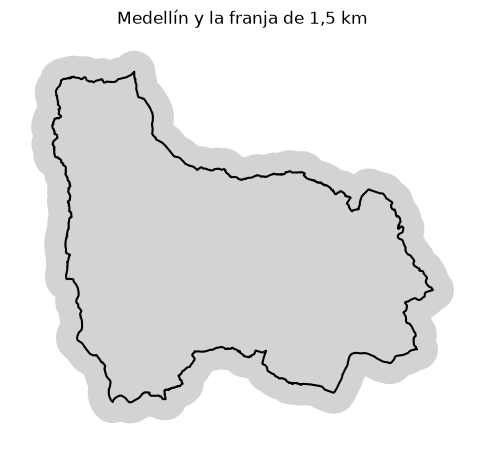

In [5]:
for intento in range(3):
    try:
        limite = ox.geocode_to_gdf(LUGAR)[["geometry"]]; break
    except Exception as e:
        if intento == 2:
            raise RuntimeError("No se pudo descargar el contorno de Medellín. Revisa la conexión y vuelve a intentar.") from e
        print("  · El servicio de búsqueda no respondió; reintentando en 20 s…"); time.sleep(20)
limite_p = limite.to_crs(CRS_PROY)
area_buffer = gpd.GeoDataFrame(geometry=limite_p.buffer(BUFFER_M), crs=CRS_PROY).to_crs(4326)
poligono_buffer = area_buffer.geometry.iloc[0]
print(f"Área de Medellín: {limite_p.area.iloc[0]/1e6:,.1f} km²")
ax = area_buffer.to_crs(CRS_PROY).plot(color="lightgrey", figsize=(6, 6))
limite_p.boundary.plot(ax=ax, color="k"); ax.set_axis_off(); ax.set_title("Medellín y la franja de 1,5 km")

## Paso 2 · El relieve: qué tan empinado es cada lugar

El **modelo digital de elevaciones** es como una foto de la altura del terreno: cada cuadrito de 30 × 30 m tiene su altura en metros. Con él calculamos la **pendiente**, es decir, qué tan empinado es cada lugar (0 % es plano; 100 % es una subida de 45°).

La pendiente importa por dos razones:
- **Caminar en subida es más lento**, así que influye en los tiempos.
- **Construir en ladera es más caro y más riesgoso.**

El archivo que tenemos cubre buena parte de Antioquia, así que primero se recorta solo la zona de Medellín.

Altura: 886 a 3,135 m · pendiente típica: 28 %


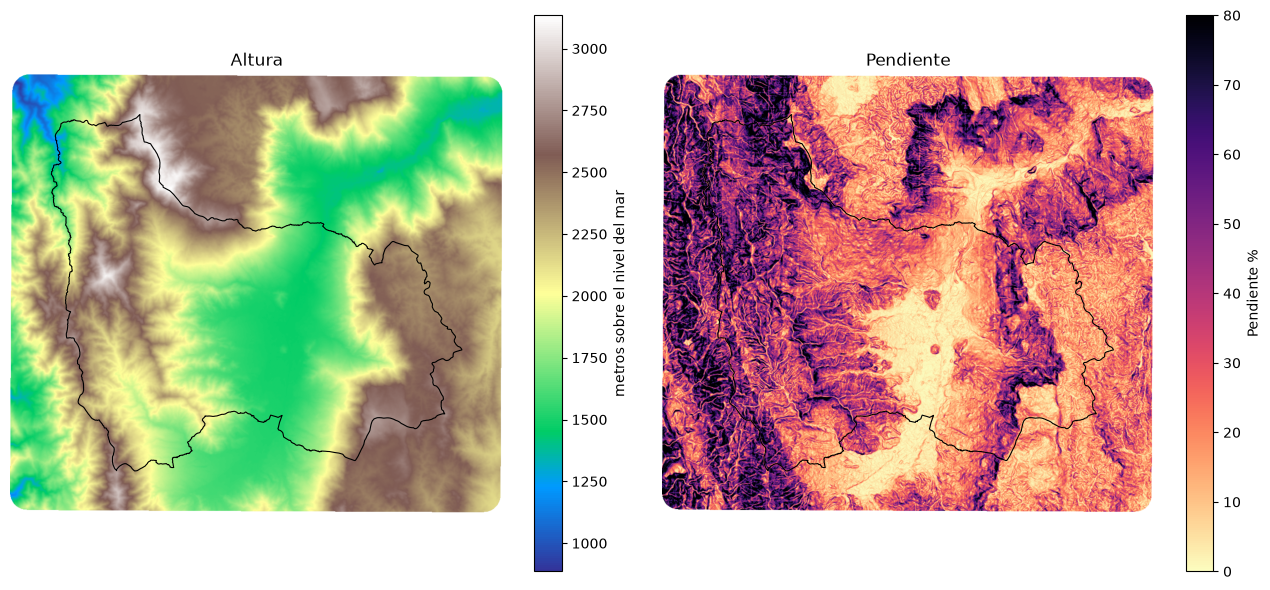

In [6]:
EQUIVALENTES_WGS84 = {4326, 4674, 4686}   # sistemas geográficos prácticamente iguales a nivel de 30 m

def reproyectar_raster(ruta_in, ruta_out, crs_destino, resolucion=None):
    with rasterio.open(ruta_in) as src:
        kw = {"resolution": resolucion} if resolucion else {}
        transf, w, h = calculate_default_transform(src.crs, crs_destino, src.width, src.height, *src.bounds, **kw)
        perfil = src.profile.copy()
        perfil.update(crs=crs_destino, transform=transf, width=w, height=h, dtype="float32")
        with rasterio.open(ruta_out, "w", **perfil) as dst:
            reproject(source=rasterio.band(src, 1), destination=rasterio.band(dst, 1),
                      src_transform=src.transform, src_crs=src.crs, dst_transform=transf, dst_crs=crs_destino,
                      resampling=Resampling.bilinear, src_nodata=src.nodata, dst_nodata=src.nodata)

def recortar_dem(ruta_dem, geom_4326, ruta_salida):
    zona = geom_4326.envelope.buffer(0.01)
    with rasterio.open(ruta_dem) as src:
        epsg = src.crs.to_epsg() if src.crs else None
        b = src.bounds
        gb = gpd.GeoSeries([zona], crs=4326).to_crs(src.crs).total_bounds
        if not (b.left <= gb[0] and b.bottom <= gb[1] and b.right >= gb[2] and b.top >= gb[3]):
            raise ValueError("El modelo de elevaciones no cubre toda Medellín.")
        nod = src.nodata if src.nodata is not None else -9999
        arr, transf = rio_mask(src, gpd.GeoSeries([zona], crs=4326).to_crs(src.crs), crop=True, filled=True, nodata=nod)
        perfil = src.profile.copy()
        perfil.update(height=arr.shape[1], width=arr.shape[2], transform=transf, nodata=nod)
    if epsg in EQUIVALENTES_WGS84:
        perfil.update(crs="EPSG:4326")
        with rasterio.open(ruta_salida, "w", **perfil) as dst:
            dst.write(arr)
        return
    tmp = ruta_salida.with_suffix(".tmp.tif")
    with rasterio.open(tmp, "w", **perfil) as dst:
        dst.write(arr)
    reproyectar_raster(tmp, ruta_salida, "EPSG:4326"); tmp.unlink()

def raster_pendiente(ruta_dem_proy, ruta_salida):
    with rasterio.open(ruta_dem_proy) as src:
        z = src.read(1).astype("float64"); nod = src.nodata; dx, dy = src.res; perfil = src.profile.copy()
    inval = ~np.isfinite(z) | (z < -100) | ((z == nod) if nod is not None else False)
    z[inval] = np.nan
    gy, gx = np.gradient(z, dy, dx)            # cuánto sube el terreno por cada metro
    p = 100 * np.sqrt(gx**2 + gy**2); p[inval] = np.nan
    perfil.update(dtype="float32", nodata=np.nan)
    with rasterio.open(ruta_salida, "w", **perfil) as dst:
        dst.write(p.astype("float32"), 1)
    return p

if not RUTA_DEM.exists():
    raise FileNotFoundError(
        f"\n\nNo encuentro el mapa de alturas.\n"
        f"Copia el archivo output_be.tif en esta carpeta:\n    {DIR_DATOS.resolve()}\n"
        f"y vuelve a ejecutar esta celda (ver datos/LEEME.md).")

RUTA_DEM_4326 = DIR_CACHE / "dem_recorte_4326.tif"
RUTA_DEM_PROY = DIR_CACHE / "dem_recorte_proy.tif"
RUTA_PEND = DIR_CACHE / "pendiente_pct.tif"
recortar_dem(RUTA_DEM, poligono_buffer, RUTA_DEM_4326)
reproyectar_raster(RUTA_DEM_4326, RUTA_DEM_PROY, CRS_PROY, resolucion=RES_PENDIENTE_M)
pend = raster_pendiente(RUTA_DEM_PROY, RUTA_PEND)
with rasterio.open(RUTA_DEM_PROY) as s:
    z = s.read(1).astype(float); z[z < -100] = np.nan
    ext = [s.bounds.left, s.bounds.right, s.bounds.bottom, s.bounds.top]
print(f"Altura: {np.nanmin(z):,.0f} a {np.nanmax(z):,.0f} m · pendiente típica: {np.nanmedian(pend):.0f} %")

fig, ax = plt.subplots(1, 2, figsize=(13, 6))
fig.colorbar(ax[0].imshow(z, extent=ext, cmap="terrain"), ax=ax[0], label="metros sobre el nivel del mar")
fig.colorbar(ax[1].imshow(np.clip(pend, 0, 80), extent=ext, cmap="magma_r"), ax=ax[1], label="Pendiente %")
for a, t in zip(ax, ["Altura", "Pendiente"]):
    limite_p.boundary.plot(ax=a, color="k", lw=0.8); a.set_title(t); a.set_axis_off()
plt.tight_layout()

## Paso 3 · Las calles y el tiempo para recorrerlas

Se descargan de **OpenStreetMap** (un mapa libre, hecho por voluntarios) todas las calles, andenes, senderos y escaleras por donde puede caminar una persona.

El mapa queda como una **red**: cada esquina es un punto y cada tramo de calle une dos esquinas. A cada tramo se le calcula **cuántos minutos se tarda una persona en recorrerlo**, teniendo en cuenta si sube o baja:

| Terreno | Velocidad caminando |
|---|---|
| Bajando suave | 6 km/h (lo más rápido) |
| Plano | 5 km/h |
| Subiendo al 20 % | 2,5 km/h |
| Subiendo al 40 % | 1,2 km/h |

Esta relación entre pendiente y velocidad se conoce como la **función de Tobler** y se usa mucho en estudios de caminata. En escaleras se camina un 30 % más lento.

Por eso, en este análisis, **500 metros en El Poblado no valen lo mismo que 500 metros subiendo en Santo Domingo**.

> **Si la descarga falla:** los servidores públicos de OpenStreetMap a veces están saturados. El notebook prueba solo con otros servidores y espera antes de reintentar. Si aun así no lo logra, espera unos minutos y vuelve a ejecutar la celda. Una vez descargada, la red queda guardada en `datos/cache/` y no se vuelve a pedir.

In [7]:
RUTA_RED = DIR_CACHE / "red_peatonal.graphml"
if RUTA_RED.exists():
    G = ox.load_graphml(RUTA_RED); print("Red de calles leída del computador")
else:
    print("Descargando las calles de OpenStreetMap (puede tardar varios minutos)…")
    G = descargar_osm(ox.graph_from_polygon, poligono_buffer, network_type="walk", retain_all=False)
    ox.save_graphml(G, RUTA_RED)
print(f"Esquinas: {G.number_of_nodes():,} · tramos de calle: {G.number_of_edges():,}")

def tobler_kmh(g):
    # Velocidad de caminata (km/h) según la pendiente g (0,10 = 10 %)
    return 6.0 * np.exp(-3.5 * np.abs(g + 0.05))

def es_escalera(hw):
    return ("steps" in hw) if isinstance(hw, list) else hw == "steps"

# Altura de cada esquina
G = ox.elevation.add_node_elevations_raster(G, RUTA_DEM_4326)
for n, d in G.nodes(data=True):
    e = d.get("elevation")
    if e is None or not np.isfinite(e) or e < -100:
        d["elevation"] = np.nan

# Pendiente, velocidad y minutos de cada tramo
for u, v, k, d in G.edges(keys=True, data=True):
    L = float(d.get("length", 0.0)); zu, zv = G.nodes[u]["elevation"], G.nodes[v]["elevation"]
    g = 0.0 if (L < LONG_MIN_PENDIENTE_M or not (np.isfinite(zu) and np.isfinite(zv))) \
        else float(np.clip((zv - zu) / L, -PENDIENTE_MAX_TRAMO, PENDIENTE_MAX_TRAMO))
    vel = tobler_kmh(g) * (FACTOR_ESCALERAS if es_escalera(d.get("highway")) else 1.0)
    d["pendiente"], d["vel_kmh"], d["t_min"] = g, vel, L / (vel * 1000 / 60)

aristas = ox.graph_to_gdfs(G, nodes=False)
print(f"Velocidad típica de caminata en Medellín: {aristas['vel_kmh'].median():.1f} km/h")

Red de calles leída del computador
Esquinas: 57,728 · tramos de calle: 160,576
Velocidad típica de caminata en Medellín: 5.0 km/h


## Paso 4 · Los destinos: a dónde necesita llegar una familia

| Destino | De dónde sale |
|---|---|
| **Sistema masivo** (metro, metrocable, tranvía, Metroplús) | Mapa oficial de la Alcaldía, solo estaciones que **ya funcionan** |
| **Paraderos de bus** | Mapa oficial de paradas autorizadas |
| **Centros de salud** | OpenStreetMap |
| **Colegios** | OpenStreetMap |

En el mapa de abajo, **revisa que no falten estaciones conocidas**. Si falta alguna, el resultado de esa zona saldrá peor de lo que es.

Estaciones del sistema masivo: 77 (mapa oficial)
Paraderos de bus: 3590 (mapa oficial)
Centros de salud: 507 · colegios: 998


Text(0.5, 1.0, 'Destinos: revisa que no falten estaciones')

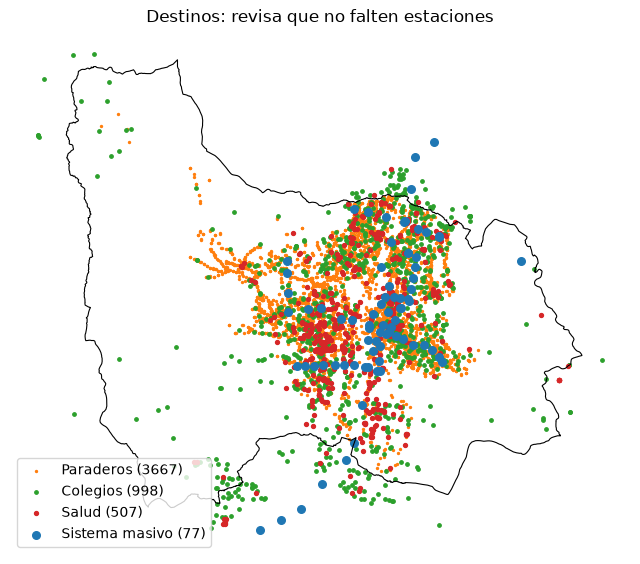

In [8]:
def leer(ruta):
    ruta = Path(ruta)
    if not ruta.exists():
        return None
    g = gpd.read_file(ruta)
    return g if g.crs is not None else g.set_crs(4326)

def puntos_osm(tags):
    try:
        f = descargar_osm(ox.features_from_polygon, poligono_buffer, tags)
    except ox._errors.InsufficientResponseError:
        return gpd.GeoDataFrame(geometry=[], crs=4326)          # no hay elementos con esas etiquetas
    except Exception as e:
        print(f"  ⚠ No se pudieron descargar {tags} de OpenStreetMap: {e}")
        return gpd.GeoDataFrame(geometry=[], crs=4326)
    f = f[["geometry"]].copy()
    f["geometry"] = f.geometry.to_crs(CRS_PROY).centroid.to_crs(4326)
    return f.reset_index(drop=True)

def como_puntos(g):
    g = g.to_crs(CRS_PROY)[["geometry"]].copy(); g["geometry"] = g.geometry.centroid
    return g.to_crs(4326)

# Sistema masivo: solo estaciones existentes
est = leer(RUTA_ESTACIONES)
if est is not None:
    if "estado" in est.columns:
        est = est[est["estado"].map(norm).isin({norm(v) for v in ESTADOS_EXISTENTES})]
    masivo = como_puntos(est); origen = "mapa oficial"
else:
    masivo = puntos_osm({"railway": ["station", "halt", "tram_stop"], "aerialway": "station",
                         "public_transport": "station"}); origen = "OpenStreetMap"
print(f"Estaciones del sistema masivo: {len(masivo)} ({origen})")

# Paraderos: la capa trae una fila por ruta y parada → se deja una por paradero
par = leer(RUTA_PARADEROS)
if par is not None:
    llave = "id_paradero" if "id_paradero" in par.columns else None
    par["_k"] = par[llave].astype(str) if llave else par.geometry.to_crs(CRS_PROY).round(-1).to_wkt()
    paraderos = como_puntos(par.drop_duplicates("_k")); origen = "mapa oficial"
else:
    paraderos = puntos_osm({"highway": "bus_stop", "public_transport": "platform"}); origen = "OpenStreetMap"
print(f"Paraderos de bus: {len(paraderos)} ({origen})")
paraderos = pd.concat([paraderos, masivo], ignore_index=True)   # una estación también sirve para tomar transporte

salud = puntos_osm({"amenity": ["hospital", "clinic", "doctors"], "healthcare": True})
educacion = puntos_osm({"amenity": ["school", "kindergarten"]})
print(f"Centros de salud: {len(salud)} · colegios: {len(educacion)}")

DESTINOS = {"t_masivo": masivo, "t_paradero": paraderos, "t_salud": salud, "t_educacion": educacion}

fig, ax = plt.subplots(figsize=(8, 9))
limite_p.boundary.plot(ax=ax, color="k", lw=0.8)
for k, c, s, lab in [("t_paradero", "tab:orange", 2, "Paraderos"), ("t_educacion", "tab:green", 6, "Colegios"),
                     ("t_salud", "tab:red", 8, "Salud"), ("t_masivo", "tab:blue", 30, "Sistema masivo")]:
    if len(DESTINOS[k]):
        DESTINOS[k].to_crs(CRS_PROY).plot(ax=ax, color=c, markersize=s, label=f"{lab} ({len(DESTINOS[k])})")
ax.legend(loc="lower left"); ax.set_axis_off(); ax.set_title("Destinos: revisa que no falten estaciones")

## Paso 5 · ¿Cuántos minutos hay caminando desde cada esquina?

Para cada esquina de Medellín se calcula cuántos minutos se tarda una persona en llegar caminando a la **estación más cercana**, al **paradero más cercano**, al **centro de salud más cercano** y al **colegio más cercano**.

**Cómo se hace, con una imagen sencilla:** imagina que en cada estación se deja caer una gota de tinta que avanza por las calles a la velocidad de una persona caminando (más lento en las subidas). Cada esquina queda marcada con el minuto en que le llegó la tinta por primera vez. Ese es su tiempo a pie hasta la estación más cercana. Esto lo hace un método llamado **algoritmo de Dijkstra**, que busca siempre el camino más rápido.

Se mide el viaje **desde la casa hacia la estación**, porque subir y bajar no tardan lo mismo.

En el mapa, cada puntico es una esquina: **verde** = cerca, **rojo** = lejos.

Hasta sistema masivo : la mitad de las esquinas está a 15.4 min o menos
Hasta paradero       : la mitad de las esquinas está a  2.8 min o menos
Hasta salud          : la mitad de las esquinas está a  6.9 min o menos
Hasta colegio        : la mitad de las esquinas está a  4.6 min o menos


Text(0.5, 1.0, 'Minutos caminando hasta el metro, cable, tranvía o Metroplús')

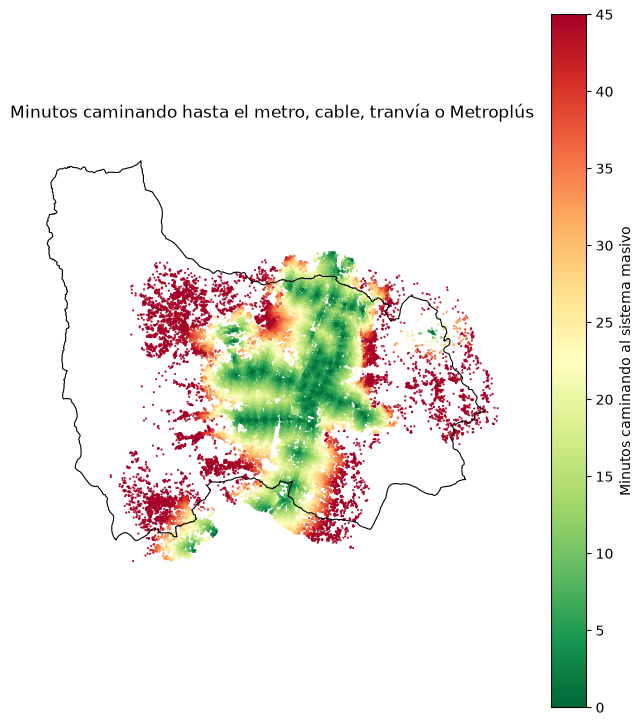

In [9]:
nodos = ox.graph_to_gdfs(G, edges=False)[["x", "y", "elevation", "geometry"]]
G_inv = G.reverse(copy=False)    # se invierte la red para medir el viaje casa → destino

def tiempo_al_mas_cercano(dest):
    if dest is None or len(dest) == 0:
        return pd.Series(np.nan, index=nodos.index)
    ns = ox.distance.nearest_nodes(G, dest.geometry.x.values, dest.geometry.y.values)
    t = nx.multi_source_dijkstra_path_length(G_inv, set(np.atleast_1d(ns)), cutoff=CORTE_MIN, weight="t_min")
    return pd.Series(t, dtype=float).reindex(nodos.index)

COLS_T = list(DESTINOS)
nombres_t = {"t_masivo": "sistema masivo", "t_paradero": "paradero", "t_salud": "salud", "t_educacion": "colegio"}
for col in COLS_T:
    nodos[col] = tiempo_al_mas_cercano(DESTINOS[col])
    print(f"Hasta {nombres_t[col]:15s}: la mitad de las esquinas está a {nodos[col].median():4.1f} min o menos")

nodos_p = nodos.to_crs(CRS_PROY)
fig, ax = plt.subplots(figsize=(8, 9))
nodos_p.plot(ax=ax, column=nodos_p["t_masivo"].clip(upper=45), cmap="RdYlGn_r", markersize=0.3,
             legend=True, legend_kwds={"label": "Minutos caminando al sistema masivo"})
limite_p.boundary.plot(ax=ax, color="k", lw=0.8); ax.set_axis_off()
ax.set_title("Minutos caminando hasta el metro, cable, tranvía o Metroplús")

### Guardar la red y los destinos para verlos en QGIS

Se guarda todo lo anterior en `resultados/red_y_destinos.gpkg`, un archivo que se abre con QGIS (programa gratuito de mapas). Allí se puede hacer zoom y consultar los minutos de cada esquina.

| Capa | Qué contiene |
|---|---|
| `nodos` | Cada esquina con su altura y sus minutos a cada destino |
| `tramos` | Cada tramo de calle con su pendiente, velocidad y minutos |
| `destinos_…` | Las estaciones, paraderos, centros de salud y colegios usados |

In [10]:
RUTA_RED_GPKG = DIR_SALIDA / "red_y_destinos.gpkg"
if RUTA_RED_GPKG.exists():
    RUTA_RED_GPKG.unlink()
nodos_p[["elevation"] + COLS_T + ["geometry"]].reset_index(names="osmid").to_file(RUTA_RED_GPKG, layer="nodos", driver="GPKG")
tramos = aristas.reset_index()
tramos = tramos[tramos["u"] < tramos["v"]]          # un solo sentido por calle
cols = ["u", "v", "length", "pendiente", "vel_kmh", "t_min", "highway", "name", "geometry"]
tramos = tramos[[c for c in cols if c in tramos.columns]].copy()
for c in ["highway", "name"]:
    if c in tramos.columns:
        tramos[c] = tramos[c].apply(lambda x: ", ".join(map(str, x)) if isinstance(x, list) else x)
tramos.to_crs(CRS_PROY).to_file(RUTA_RED_GPKG, layer="tramos", driver="GPKG")
for col, capa in {"t_masivo": "destinos_masivo", "t_paradero": "destinos_paraderos",
                  "t_salud": "destinos_salud", "t_educacion": "destinos_colegios"}.items():
    if len(DESTINOS[col]):
        DESTINOS[col][["geometry"]].to_crs(CRS_PROY).to_file(RUTA_RED_GPKG, layer=capa, driver="GPKG")
print(f"Guardado: {RUTA_RED_GPKG}")

Guardado: resultados\red_y_destinos.gpkg


## Paso 6 · Dividir la ciudad en hexágonos

Para comparar zonas, Medellín se divide en **hexágonos iguales**, como un panal de abejas. Cada hexágono mide unas **2,6 hectáreas** (más o menos dos o tres manzanas).

A cada hexágono se le asigna:
- **Minutos a cada destino:** los de la esquina más cercana a su centro, más lo que se tarda en llegar a esa esquina caminando (a 3 km/h, porque puede no haber andén).
- **Distancia a la calle más cercana:** si es grande, ese terreno todavía no tiene vías.
- **Pendiente promedio** del terreno.

Si desde un hexágono no se alcanza un destino en 120 minutos, se le asignan 120 minutos ("120 o más"), para que cuente como mal conectado.

In [11]:
def malla_hex(geom, R, crs):
    minx, miny, maxx, maxy = geom.bounds
    dx, dy = 1.5 * R, np.sqrt(3) * R
    ang = np.deg2rad(np.arange(0, 360, 60)); vx, vy = R * np.cos(ang), R * np.sin(ang)
    polys, cents = [], []
    for i, cx in enumerate(np.arange(minx - R, maxx + 2 * R, dx)):
        off = dy / 2 if i % 2 else 0.0
        for cy in np.arange(miny - dy, maxy + dy, dy) + off:
            polys.append(Polygon(zip(cx + vx, cy + vy))); cents.append(Point(cx, cy))
    g = gpd.GeoDataFrame(geometry=polys, crs=crs)
    g = g[gpd.GeoSeries(cents, crs=crs).within(geom).values].reset_index(drop=True)
    g.index.name = "hex_id"
    return g

hexes = malla_hex(limite_p.geometry.iloc[0], RADIO_HEX_M, CRS_PROY)
hexes["area_ha"] = hexes.area / 1e4
AREA_HEX = hexes["area_ha"].iloc[0]
centros = gpd.GeoDataFrame(geometry=hexes.centroid, crs=CRS_PROY)
print(f"Hexágonos: {len(hexes):,} de {AREA_HEX:.1f} ha cada uno")

# Esquina más cercana a cada hexágono y sus minutos
near = gpd.sjoin_nearest(centros, nodos_p[["geometry"]].reset_index(names="nodo"), how="left", distance_col="dist_a_red")
near = near[~near.index.duplicated()]
hexes["nodo"] = near["nodo"].values
hexes["dist_a_red"] = near["dist_a_red"].values
t_fuera = (hexes["dist_a_red"] / (V_FUERA_RED_KMH * 1000 / 60)).values
for col in COLS_T:
    hexes[col] = nodos.loc[hexes["nodo"], col].values + t_fuera
hexes["sin_acceso_masivo"] = hexes["t_masivo"].isna()
for col in COLS_T:
    n = hexes[col].isna().sum()
    if n:
        print(f"  {nombres_t[col]}: {n:,} hexágonos sin acceso en {CORTE_MIN} min → se les asignan {CORTE_MIN} min")
hexes[COLS_T] = hexes[COLS_T].fillna(CORTE_MIN).clip(upper=CORTE_MIN)

# Pendiente promedio de cada hexágono
with rasterio.open(RUTA_PEND) as s:
    P = s.read(1); T = s.transform
f_, c_ = np.where(np.isfinite(P))
xs, ys = rasterio.transform.xy(T, f_, c_)
pix = gpd.GeoDataFrame({"p": P[f_, c_]}, geometry=gpd.points_from_xy(xs, ys), crs=CRS_PROY)
pix = gpd.sjoin(pix, hexes[["geometry"]].reset_index(), predicate="within")
hexes["pendiente_media"] = pix.groupby("hex_id")["p"].mean().reindex(hexes.index)
hexes[["dist_a_red", "pendiente_media"] + COLS_T].describe().round(1)

Hexágonos: 14,418 de 2.6 ha cada uno
  sistema masivo: 4,469 hexágonos sin acceso en 120 min → se les asignan 120 min
  paradero: 1,814 hexágonos sin acceso en 120 min → se les asignan 120 min
  salud: 2,788 hexágonos sin acceso en 120 min → se les asignan 120 min
  colegio: 56 hexágonos sin acceso en 120 min → se les asignan 120 min


,dist_a_red,pendiente_media,t_masivo,t_paradero,t_salud,t_educacion
count,14418.0,14418.0,14418.0,14418.0,14418.0,14418.0
mean,229.1,31.9,71.5,48.5,56.1,28.8
std,347.9,19.0,43.4,43.6,43.7,27.0
min,0.5,0.6,0.5,0.0,0.1,0.1
25%,39.2,16.6,27.8,5.9,12.8,7.9
50%,102.6,29.9,74.8,36.9,48.8,21.2
75%,269.5,44.9,120.0,86.2,100.4,40.7
max,3404.3,104.9,120.0,120.0,120.0,120.0


## Paso 7 · Encontrar los barrios en riesgo

Este es el **punto de partida** del análisis: ¿de dónde salen las familias?

Un hexágono se considera parte de un barrio en riesgo si cumple al menos una de estas condiciones:

| Condición | Fuente | Por qué |
|---|---|---|
| Está a 100 m o menos de una **zona de alto riesgo no mitigable** | Mapas de riesgo del POT | Son los lugares donde ninguna obra resuelve el peligro y la norma obliga a reasentar |
| Está en una zona de **Mejoramiento Integral** | Tratamientos del POT | El POT marca así los barrios de origen informal, con carencias de vivienda e infraestructura |

Luego, las zonas cercanas entre sí (a menos de 300 m) se agrupan en un mismo **barrio en riesgo** (en el código se llama *territorio*). Si un grupo es muy grande, se divide en partes del tamaño de unos pocos barrios.

Para cada barrio en riesgo se guarda **cómo está conectado hoy**: cuántos minutos hay, en el caso típico, hasta el metro, el paradero, la salud y el colegio. Esa es la referencia para que el sitio nuevo **no deje a las familias peor de lo que están**.

In [12]:
def poligonos_con(capa):
    # Polígonos de un mapa cuyo valor contiene alguna de las palabras buscadas
    if capa is None:
        return None
    g = leer(capa["ruta"])
    if g is None:
        print(f"  ! Falta {Path(capa['ruta']).name}"); return None
    if capa["columna"] not in g.columns:
        print(f"  ! {Path(capa['ruta']).name}: no tiene la columna {capa['columna']}. Columnas: {list(g.columns)}"); return None
    vals = g[capa["columna"]].map(norm)
    ok = vals.apply(lambda v: any(norm(p) in v for p in capa["palabras"]))
    if not ok.any():
        print(f"  ! {Path(capa['ruta']).name}: ningún valor contiene {capa['palabras']}. Valores: {sorted(vals.unique())[:15]}")
        return None
    return g[ok][["geometry"]].to_crs(CRS_PROY)

def centro_dentro(capa_p):
    # True para los hexágonos cuyo centro cae dentro de algún polígono del mapa
    j = gpd.sjoin(centros, capa_p[["geometry"]].reset_index(drop=True), predicate="within", how="inner")
    return pd.Series(hexes.index.isin(j.index), index=hexes.index)

fuentes = []
hexes["vulnerable"] = False

riesgo = [p for p in (poligonos_con(c) for c in CAPAS_RIESGO) if p is not None]
if riesgo:
    zr = pd.concat(riesgo, ignore_index=True)
    hexes["vulnerable"] |= centro_dentro(gpd.GeoDataFrame(geometry=zr.buffer(RADIO_RIESGO_M), crs=CRS_PROY))
    fuentes.append(f"zonas de alto riesgo no mitigable ({len(zr)})")

mi = poligonos_con(CAPA_MEJORAMIENTO)
if mi is not None:
    hexes["vulnerable"] |= centro_dentro(mi); fuentes.append("Mejoramiento Integral")

MODO_DEMO = len(fuentes) == 0
if MODO_DEMO:
    # Sin mapas oficiales: aproximación con laderas construidas y lejos del masivo (solo para probar)
    hexes["vulnerable"] = (hexes["pendiente_media"] > 25) & (hexes["dist_a_red"] < 50) & (hexes["t_masivo"] > 15)
    print("⚠ MODO DEMOSTRACIÓN: no se encontraron los mapas de riesgo. Los barrios son una aproximación.")
else:
    print("Fuentes usadas:", ", ".join(fuentes))
print(f"Hexágonos en barrios en riesgo: {hexes['vulnerable'].sum():,} ({hexes['vulnerable'].mean():.1%} de la ciudad)")

Fuentes usadas: zonas de alto riesgo no mitigable (305), Mejoramiento Integral
Hexágonos en barrios en riesgo: 784 (5.4% de la ciudad)


In [13]:
# --- Agrupar en barrios en riesgo (territorios)
vul = hexes[hexes["vulnerable"]]
if vul.empty:
    raise ValueError("No se encontraron barrios en riesgo: revisa el paso 0.")
union = vul.buffer(DIST_UNION_TERRITORIOS_M / 2).union_all()
grupos = gpd.GeoDataFrame(geometry=[union], crs=CRS_PROY).explode(index_parts=False).reset_index(drop=True)
grupos["gid"] = np.arange(len(grupos))
j = gpd.sjoin(centros.loc[vul.index], grupos, predicate="within")
grupo = pd.Series(j["gid"], index=j.index)

# Grupos muy grandes → se dividen en partes del tamaño de unos pocos barrios
from scipy.cluster.vq import kmeans2
tid_final, nuevo = pd.Series(np.nan, index=hexes.index), 1
for gid, idx in grupo.groupby(grupo).groups.items():
    k = int(np.ceil(len(idx) * AREA_HEX / AREA_MAX_TERRITORIO_HA))
    if k <= 1:
        tid_final.loc[idx] = nuevo; nuevo += 1; continue
    xy = np.c_[centros.loc[idx].geometry.x, centros.loc[idx].geometry.y]
    _, etq = kmeans2(xy, k, seed=1, minit="++")
    for e in np.unique(etq):
        tid_final.loc[np.asarray(idx)[etq == e]] = nuevo; nuevo += 1
hexes["tid"] = tid_final

# Cómo está conectado hoy cada barrio (caso típico = mediana)
reg = []
for tid, h in hexes[hexes["tid"].notna()].groupby("tid"):
    fila = {"tid": int(tid), "area_ha": h["area_ha"].sum(), "geometry": h.buffer(1).union_all()}
    for c in COLS_T:
        fila[f"hoy_{c}"] = h[c].median()
    fila["pendiente"] = h["pendiente_media"].mean()
    reg.append(fila)
territorios = gpd.GeoDataFrame(reg, geometry="geometry", crs=CRS_PROY).set_index("tid")
territorios = territorios[territorios["area_ha"] >= AREA_MIN_TERRITORIO_HA]
print(f"Barrios en riesgo identificados: {len(territorios)}")
territorios.drop(columns="geometry").round(1).sort_values("area_ha", ascending=False).head(15)

Barrios en riesgo identificados: 32


,area_ha,hoy_t_masivo,hoy_t_paradero,hoy_t_salud,hoy_t_educacion,pendiente
tid,,,,,,
9,187.1,27.3,2.7,15.2,7.8,30.600000
30,155.9,42.7,5.1,11.9,7.3,42.200001
26,140.3,25.0,5.3,27.1,9.7,37.599998
8,140.3,17.7,2.6,23.7,8.5,31.200001
27,129.9,9.4,2.2,11.3,5.2,30.200001
25,114.3,34.3,4.6,13.2,6.5,35.400002
29,111.7,24.2,4.4,13.7,6.8,41.200001
31,106.5,15.2,5.0,8.5,5.8,36.599998
7,101.3,46.8,3.6,17.1,18.0,25.299999


Text(0.5, 1.0, 'Barrios en riesgo y su conexión actual')

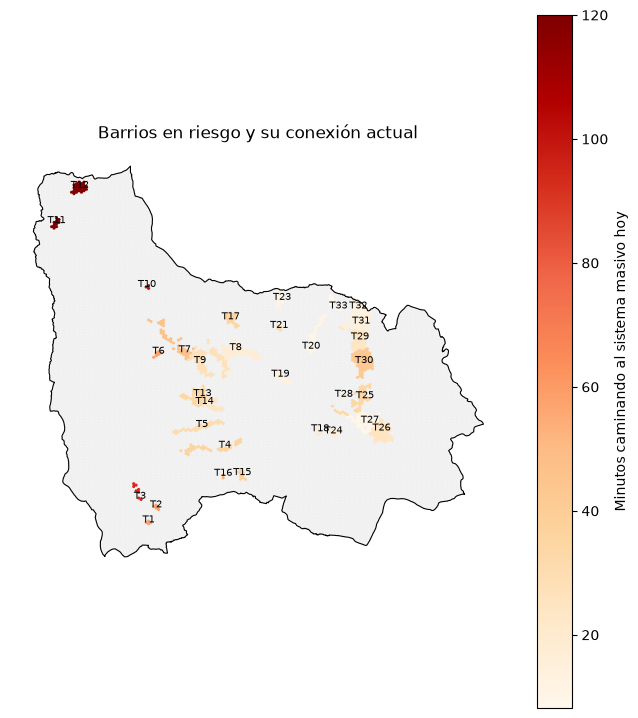

In [14]:
fig, ax = plt.subplots(figsize=(8, 9))
hexes.plot(ax=ax, color="#f0f0f0")
territorios.plot(ax=ax, column="hoy_t_masivo", cmap="OrRd", legend=True,
                 legend_kwds={"label": "Minutos caminando al sistema masivo hoy"})
for tid, t in territorios.iterrows():
    p = t.geometry.representative_point(); ax.annotate(f"T{tid}", (p.x, p.y), fontsize=7, ha="center")
limite_p.boundary.plot(ax=ax, color="k", lw=0.8); ax.set_axis_off()
ax.set_title("Barrios en riesgo y su conexión actual" + ("  (MODO DEMOSTRACIÓN)" if MODO_DEMO else ""))

## Paso 8 · Descartar el terreno donde no se puede construir

Antes de calificar, se descarta el terreno que **no sirve**, sin importar qué tan bien conectado esté. Un hexágono queda **descartado** si:

| Regla | Por qué |
|---|---|
| Más del 10 % está en **amenaza alta** | No tiene sentido sacar a una familia de un riesgo para ponerla en otro |
| Está en **suelo de protección** (áreas protegidas, retiros a quebradas, humedales) | La ley no permite ocuparlo |
| No es suelo donde el POT permite **vivienda nueva** (renovación, desarrollo o mejoramiento integral) | Hay que respetar el ordenamiento de la ciudad |
| Su pendiente promedio pasa de **30 %** | Construir ahí exige obras muy costosas |
| Está a más de **800 m** de cualquier camino | No hay forma realista de conectarlo pronto |

Que el mejoramiento integral cuente como suelo posible permite **reubicar a las familias en la parte segura de su mismo barrio**, sin alejarlas.

Al final, cada hexágono queda marcado como **elegible** (sirve) o con el **motivo** por el que se descartó.

In [15]:
hexes["frac_amenaza"] = 0.0
filtros = []
for capa in CAPAS_AMENAZA:
    g = leer(capa["ruta"])
    if g is None or capa["columna"] not in g.columns:
        print(f"  ! Falta el mapa de amenaza por {capa['nombre'].lower()}"); continue
    alta = g[g[capa["columna"]].map(norm).isin({norm(v) for v in capa["valores_altos"]})].to_crs(CRS_PROY)
    if alta.empty:
        print(f"  ! {capa['nombre']}: no hay zonas 'Alta'. Valores: {sorted(g[capa['columna']].astype(str).unique())[:15]}"); continue
    inter = gpd.overlay(hexes.reset_index()[["hex_id", "geometry"]],
                        gpd.GeoDataFrame(geometry=[alta.union_all()], crs=CRS_PROY), how="intersection")
    frac = (inter.area / (AREA_HEX * 1e4)).groupby(inter["hex_id"]).sum()
    hexes["frac_amenaza"] = np.maximum(hexes["frac_amenaza"], frac.reindex(hexes.index).fillna(0))
    filtros.append(capa["nombre"])

prot = [g.to_crs(CRS_PROY)[["geometry"]] for g in (leer(r) for r in CAPAS_PROTECCION) if g is not None]
hexes["en_proteccion"] = centro_dentro(pd.concat(prot, ignore_index=True)) if prot else False
if prot: filtros.append("Suelo de protección")

aptas = [p for p in (poligonos_con(c) for c in CAPAS_SUELO_APTO) if p is not None]
if aptas:
    hexes["suelo_apto"] = centro_dentro(pd.concat(aptas, ignore_index=True)); filtros.append("Suelo apto")
else:
    hexes["suelo_apto"] = True
    print("  ! Sin mapa de tratamientos: se evalúa todo el suelo")

POT_COMPLETO = {"Movimientos en masa", "Inundación", "Avenidas torrenciales"} <= set(filtros)
motivos = {"amenaza alta": hexes["frac_amenaza"] > FRAC_AMENAZA_MAX,
           "suelo de protección": hexes["en_proteccion"].astype(bool),
           "el POT no permite vivienda nueva": ~hexes["suelo_apto"].astype(bool),
           "pendiente mayor a 30 %": hexes["pendiente_media"].fillna(999) > PENDIENTE_MAX_PCT,
           "lejos de cualquier camino": hexes["dist_a_red"] > DIST_RED_MAX_M}
hexes["motivo_descarte"] = ""
for m, msk in motivos.items():
    hexes.loc[msk & (hexes["motivo_descarte"] == ""), "motivo_descarte"] = m
hexes["elegible"] = hexes["motivo_descarte"] == ""

print("Filtros aplicados:", ", ".join(filtros) or "ninguno")
if not POT_COMPLETO:
    print("⚠ RESULTADO PROVISIONAL: faltan mapas de amenaza.")
print(hexes["motivo_descarte"].replace("", "SIRVE (elegible)").value_counts().to_string())

Filtros aplicados: Movimientos en masa, Inundación, Avenidas torrenciales, Suelo de protección, Suelo apto
motivo_descarte
suelo de protección                 6584
el POT no permite vivienda nueva    4470
amenaza alta                        2814
SIRVE (elegible)                     452
pendiente mayor a 30 %                98


Text(0.5, 1.0, '¿Dónde se puede construir?')

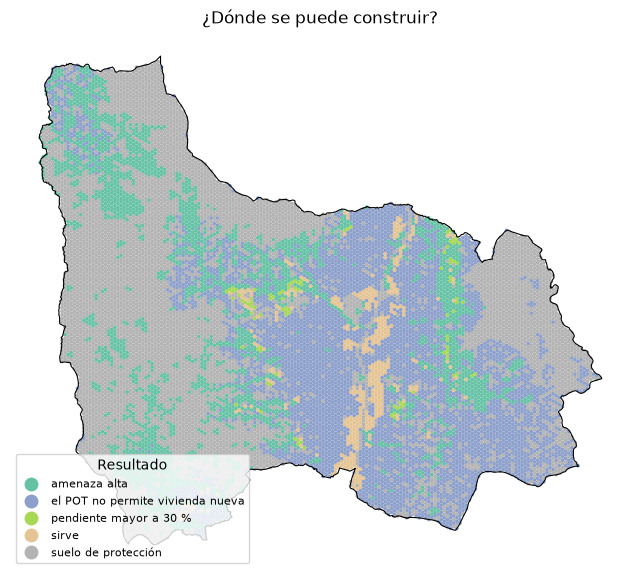

In [16]:
fig, ax = plt.subplots(figsize=(8, 9))
hexes.assign(resultado=hexes["motivo_descarte"].replace("", "sirve")).plot(
    ax=ax, column="resultado", categorical=True, legend=True, cmap="Set2",
    legend_kwds={"loc": "lower left", "title": "Resultado", "fontsize": 8})
limite_p.boundary.plot(ax=ax, color="k", lw=0.8); ax.set_axis_off()
ax.set_title("¿Dónde se puede construir?")

## Paso 9 · Calificar cada terreno (primera parte)

Cada terreno que sirve recibe una calificación de **0 a 1** en cinco criterios (1 es lo mejor). Los dos primeros dependen solo del terreno:

### C1 · ¿Cuánto cuesta conectarlo? (30 % de la nota)

Se fija un **mínimo para el día de la mudanza**:
- un paradero de bus a **10 minutos** o menos caminando, y
- el metro, cable, tranvía o Metroplús a **20 minutos** o menos.

Para cada terreno se suman las obras que faltan para cumplir ese mínimo:

| Si falta… | Obra | Costo (unidades) |
|---|---|---|
| Calle o sendero hasta el terreno | Construir el acceso | 1 por metro (más en ladera) |
| Paradero cerca | Paradero nuevo o ajustar una ruta | 150 |
| Masivo cerca (20 a 30 min) | Escaleras, andenes, cubiertas | 40 por minuto que sobra |
| Masivo cerca (más de 30 min) | Una ruta de bus que lleve al masivo | 600 |

**Un terreno que ya cumple el mínimo no necesita obras y saca 1.** Entre más obras necesite, menos puntos.

### C4 · ¿A quién más le sirven esas obras? (20 % de la nota)

Se cuentan las hectáreas de **barrios en riesgo que hoy no cumplen el mínimo** y que están a 800 m o menos del terreno. Esos vecinos también podrían usar la escalera, el paradero o la ruta nueva. **Entre más vecinos beneficiados, más puntos.**

> Los costos están en unidades relativas, no en pesos. Sirven para comparar terrenos entre sí; para un presupuesto real hay que calibrarlos.

In [17]:
pend_frac = hexes["pendiente_media"].fillna(0) / 100
exceso_par = (hexes["t_paradero"] - PISO_PARADERO_MIN).clip(lower=0)
exceso_mas = (hexes["t_masivo"] - PISO_MASIVO_MIN).clip(lower=0)

hexes["costo_via"] = COSTOS["via_m"] * hexes["dist_a_red"] * (1 + COSTOS["factor_pendiente"] * pend_frac)
hexes["costo_paradero"] = np.where(exceso_par > 0, COSTOS["paradero_o_ruta"], 0)
hexes["costo_masivo"] = np.where(exceso_mas > 10, COSTOS["alimentadora"], COSTOS["peatonal_por_min"] * exceso_mas)
hexes["costo_obras"] = hexes[["costo_via", "costo_paradero", "costo_masivo"]].sum(axis=1)

eleg = hexes["elegible"]
tope = hexes.loc[eleg, "costo_obras"].quantile(0.95) or 1     # valor que solo supera el 5 % de los terrenos
hexes["c1_conectabilidad"] = (1 - hexes["costo_obras"] / tope).clip(0, 1)

# C4: barrios en riesgo que hoy no cumplen el mínimo, a 800 m o menos
deficit = hexes["vulnerable"] & ((hexes["t_paradero"] > PISO_PARADERO_MIN) | (hexes["t_masivo"] > PISO_MASIVO_MIN))
circulos = gpd.GeoDataFrame(geometry=centros.loc[eleg].buffer(RADIO_BENEFICIO_M), crs=CRS_PROY)
jd = gpd.sjoin(circulos, centros.loc[deficit].reset_index(names="h_def"), predicate="contains")
hexes["beneficio_ha"] = (jd.groupby(level=0).size() * AREA_HEX).reindex(hexes.index).fillna(0)
tope_b = hexes.loc[eleg, "beneficio_ha"].quantile(0.95) or 1
hexes["c4_beneficio"] = (hexes["beneficio_ha"] / tope_b).clip(0, 1)
print(f"Hexágonos de barrios en riesgo que hoy no cumplen el mínimo: {deficit.sum():,}")

Hexágonos de barrios en riesgo que hoy no cumplen el mínimo: 513


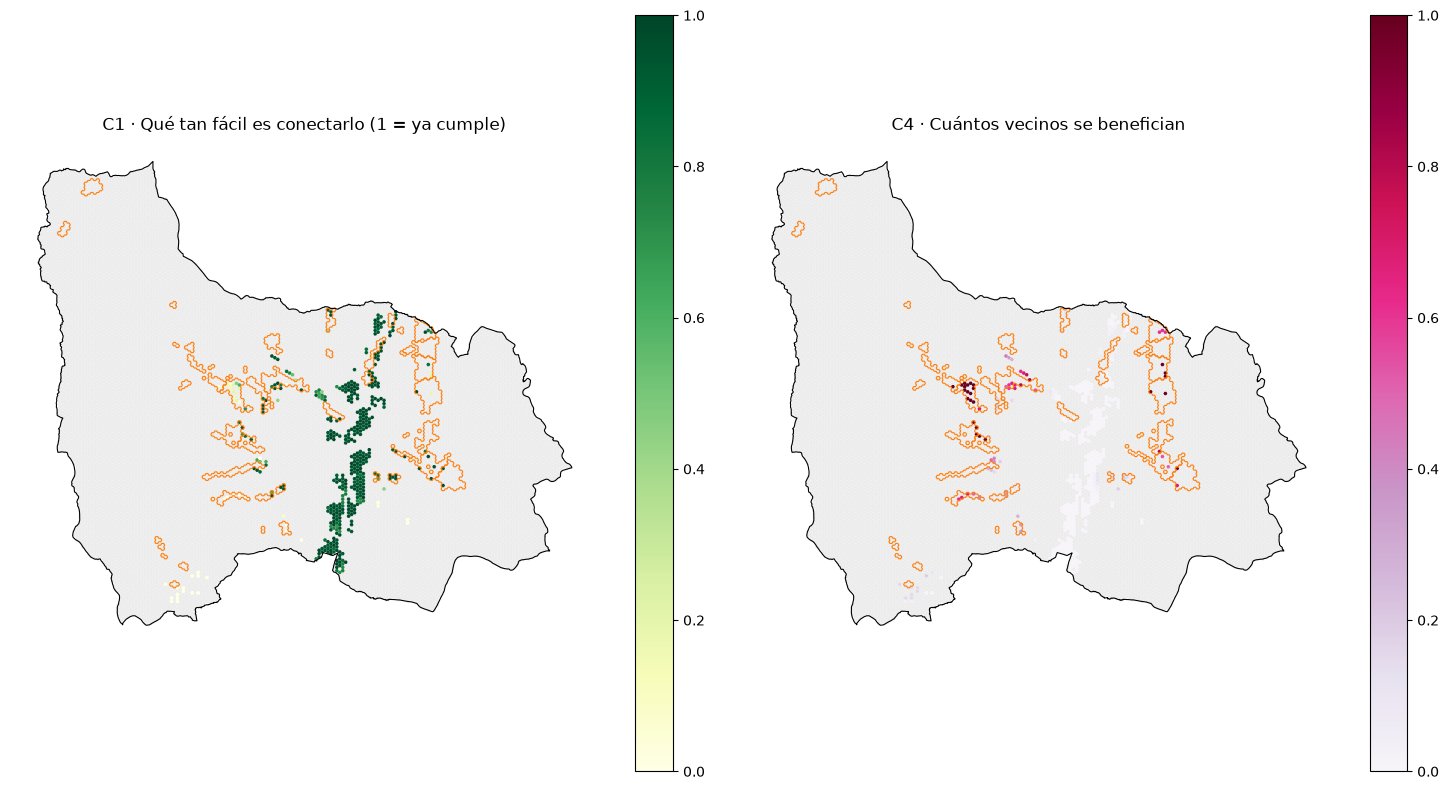

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(15, 8))
for a, col, cm, t in [(ax[0], "c1_conectabilidad", "YlGn", "C1 · Qué tan fácil es conectarlo (1 = ya cumple)"),
                      (ax[1], "c4_beneficio", "PuRd", "C4 · Cuántos vecinos se benefician")]:
    hexes[~eleg].plot(ax=a, color="#ececec")
    hexes[eleg].plot(ax=a, column=col, cmap=cm, vmin=0, vmax=1, legend=True)
    territorios.boundary.plot(ax=a, color="tab:orange", lw=0.8)
    limite_p.boundary.plot(ax=a, color="k", lw=0.8); a.set_axis_off(); a.set_title(t)
plt.tight_layout()

## Paso 10 · Calificar cada terreno para cada barrio (segunda parte)

Ahora entra el barrio de origen. Para **cada barrio en riesgo** se miran los terrenos que sirven a **2,5 km o menos**, incluidos los que están dentro del mismo barrio. Cada par "barrio – terreno" recibe tres calificaciones más:

### C2 · ¿Las familias quedan igual o mejor que hoy? (20 %)
Se comparan los minutos desde el terreno nuevo con los minutos que tiene hoy el barrio, para el metro, el paradero, la salud y el colegio. Si el terreno queda **igual o mejor**, saca 1. Si queda **15 minutos peor o más**, saca 0. Quedar mejor no da puntos extra: el objetivo es **no empeorar**.

### C3 · ¿Queda cerca del barrio? (20 %)
A **500 m o menos** (o dentro del mismo barrio): 1 punto. A **2,5 km**: 0. Las familias conservan su trabajo, el colegio de los niños y sus vecinos.

### C5 · ¿Qué tan empinado es? (10 %)
Pendiente de **10 % o menos**: 1 punto. **30 %**: 0.

### La nota final
$$\text{Nota} = 0{,}30\cdot C_1 + 0{,}20\cdot C_2 + 0{,}20\cdot C_3 + 0{,}20\cdot C_4 + 0{,}10\cdot C_5$$

**Ejemplo:** un terreno a 700 m del barrio, que necesita pocas obras (C1 = 0,73), deja a las familias casi igual (C2 = 0,91), está cerca (C3 = 0,90), ayuda a bastantes vecinos (C4 = 0,67) y es algo empinado (C5 = 0,60). Su nota es **0,78**: un buen candidato.

In [19]:
def lineal(x, bueno, malo):
    # 1 si x es igual o mejor que 'bueno'; 0 si es igual o peor que 'malo'; proporcional en medio
    return ((malo - x) / (malo - bueno)).clip(0, 1)

hexes["c5_pendiente"] = lineal(hexes["pendiente_media"].fillna(PENDIENTE_MALA), PENDIENTE_BUENA, PENDIENTE_MALA)

filas = []
cent_eleg = centros.loc[eleg]
for tid, t in territorios.iterrows():
    dist = cent_eleg.distance(t.geometry)
    cerca = dist[dist <= RADIO_BUSQUEDA_M]
    if cerca.empty:
        continue
    h = hexes.loc[cerca.index]
    c2 = sum(w * (1 - ((h[k] - t[f"hoy_{k}"]).clip(lower=0) / EMPEORAR_MAX_MIN)).clip(0, 1)
             for k, w in PESOS_NO_EMPEORAR.items()) / sum(PESOS_NO_EMPEORAR.values())
    filas.append(pd.DataFrame({
        "tid": tid, "hex_id": cerca.index, "dist_barrio_m": cerca.values,
        "c1_conectabilidad": h["c1_conectabilidad"].values, "c2_no_empeorar": c2.values,
        "c3_cercania": lineal(cerca, DIST_BUENA_M, RADIO_BUSQUEDA_M).values,
        "c4_beneficio": h["c4_beneficio"].values, "c5_pendiente": h["c5_pendiente"].values}))
pares = pd.concat(filas, ignore_index=True)
pares["nota"] = sum(PESOS[k] * pares[k] for k in PESOS)

sin_terreno = sorted(set(territorios.index) - set(pares["tid"]))
print(f"Combinaciones barrio–terreno evaluadas: {len(pares):,}")
if sin_terreno:
    print(f"⚠ Barrios SIN terreno seguro a {RADIO_BUSQUEDA_M/1000:.1f} km o menos: {sin_terreno} "
          "→ necesitan otra estrategia (obras de mitigación, buscar más lejos o habilitar suelo nuevo)")

Combinaciones barrio–terreno evaluadas: 1,597
⚠ Barrios SIN terreno seguro a 2.5 km o menos: [10, 11, 12] → necesitan otra estrategia (obras de mitigación, buscar más lejos o habilitar suelo nuevo)


## Paso 11 · Elegir los mejores sitios para cada barrio

Para cada barrio, los hexágonos vecinos con nota de **0,60 o más** se juntan para formar **sitios**:
- Si un sitio queda muy grande (más de 40 ha), se queda con su mejor parte.
- Si queda muy pequeño (menos de 3 ha), se descarta, porque no alcanza para un proyecto.
- Si un barrio no tiene ningún sitio con 0,60, se toman sus mejores terrenos y se indica en la tabla.

Se proponen **los 2 mejores sitios por barrio**.

In [20]:
def componentes(sub):
    # Agrupa los hexágonos que se tocan
    if sub.empty:
        return []
    u = sub.buffer(1).union_all()
    partes = gpd.GeoDataFrame(geometry=[u], crs=CRS_PROY).explode(index_parts=False).reset_index(drop=True)
    jj = gpd.sjoin(gpd.GeoDataFrame(geometry=sub.centroid, crs=CRS_PROY), partes, predicate="within")
    return [g.index.values for _, g in jj.groupby("index_right")]

def zonificar(sub, umbral):
    # Forma sitios; si uno es muy grande, sube la exigencia dentro de él para quedarse con su núcleo
    out = []
    for idx in componentes(sub[sub["nota"] >= umbral]):
        if sub.loc[idx, "area_ha"].sum() > AREA_MAX_SITIO_HA and umbral < 0.99:
            out += zonificar(sub.loc[idx], round(umbral + 0.02, 2))
        else:
            out.append(idx)
    return out

sitios, hex_sitio = [], []
for tid, pt in pares.groupby("tid"):
    sub = hexes.loc[pt["hex_id"].values, ["geometry", "area_ha"]].copy()
    sub["nota"] = pt["nota"].values
    umbral, relajado = UMBRAL_INDICE, False
    grupos = [g for g in zonificar(sub, umbral) if sub.loc[g, "area_ha"].sum() >= AREA_MIN_SITIO_HA]
    if not grupos:
        umbral, relajado = round(float(sub["nota"].quantile(0.8)), 3), True
        grupos = [g for g in zonificar(sub, umbral) if sub.loc[g, "area_ha"].sum() >= AREA_MIN_SITIO_HA]
    cand = sorted(((sub.loc[g, "nota"].mean() * np.log1p(sub.loc[g, "area_ha"].sum()), g) for g in grupos),
                  key=lambda x: -x[0])[:SITIOS_POR_TERRITORIO]
    for k, (_, g) in enumerate(cand, start=1):
        sid = f"T{tid}-S{k}"
        pg = pt.set_index("hex_id").loc[g]; h = hexes.loc[g]
        fila = {"sitio": sid, "tid": tid, "orden": k, "area_ha": h["area_ha"].sum(), "nota": pg["nota"].mean(),
                "umbral": umbral, "exigencia_reducida": relajado, "dist_barrio_m": pg["dist_barrio_m"].mean(),
                "costo_obras": h["costo_obras"].mean(), "beneficio_ha": h["beneficio_ha"].mean(),
                "pendiente_media": h["pendiente_media"].mean(), "dist_a_red": h["dist_a_red"].mean(),
                "geometry": h.buffer(1).union_all()}
        for c in PESOS:
            fila[c] = pg[c].mean()
        for c in COLS_T:
            fila[c] = h[c].median(); fila[f"hoy_{c}"] = territorios.loc[tid, f"hoy_{c}"]
        sitios.append(fila)
        hex_sitio.append(pd.DataFrame({"sitio": sid, "tid": tid, "hex_id": g}))

sitios = gpd.GeoDataFrame(sitios, geometry="geometry", crs=CRS_PROY).set_index("sitio")
hex_sitio = pd.concat(hex_sitio, ignore_index=True) if hex_sitio else pd.DataFrame(columns=["sitio", "tid", "hex_id"])
print(f"Sitios propuestos: {len(sitios)} para {sitios['tid'].nunique()} de {len(territorios)} barrios en riesgo")
sitios[["tid", "area_ha", "nota", "dist_barrio_m", "exigencia_reducida"]].round(2).head(20)

Sitios propuestos: 48 para 25 de 32 barrios en riesgo


,tid,area_ha,nota,dist_barrio_m,exigencia_reducida
sitio,,,,,
T4-S1,4,7.79,0.76,0.00,False
T4-S2,4,7.79,0.74,1212.14,False
T5-S1,5,7.79,0.81,123.40,False
T5-S2,5,7.79,0.68,1346.27,False
T6-S1,6,5.20,0.58,2374.77,True
T7-S1,7,25.98,0.69,422.59,False
T7-S2,7,7.79,0.62,2381.55,False
T8-S1,8,15.59,0.79,42.80,False
T8-S2,8,23.38,0.69,635.97,False


### ¿Tiene dos salidas para emergencias?

Un barrio nuevo necesita **al menos dos vías independientes** para que entren ambulancias y bomberos, y para evacuar si una se bloquea. Se descarga la red de calles para carros y se cuenta cuántos caminos sin tramos compartidos hay entre cada sitio y el centro de la ciudad (hasta 2).

In [21]:
from networkx.algorithms.connectivity import local_edge_connectivity
RUTA_RED_VEH = DIR_CACHE / "red_vehicular.graphml"
if RUTA_RED_VEH.exists():
    Gd = ox.load_graphml(RUTA_RED_VEH)
else:
    print("Descargando la red para carros de OpenStreetMap…")
    Gd = descargar_osm(ox.graph_from_polygon, poligono_buffer, network_type="drive"); ox.save_graphml(Gd, RUTA_RED_VEH)
H = nx.Graph(ox.convert.to_undirected(Gd))
nodo_centro = ox.distance.nearest_nodes(Gd, CENTRO_REF[1], CENTRO_REF[0])
c4326 = gpd.GeoSeries(sitios.geometry.centroid, crs=CRS_PROY).to_crs(4326)
nn, dd = ox.distance.nearest_nodes(Gd, c4326.x.values, c4326.y.values, return_dist=True)
sitios["dist_via_carros_m"] = np.round(dd, 0)
sitios["salidas_vehiculares"] = [CORTE_RUTAS_VEH if n == nodo_centro else
                                 local_edge_connectivity(H, n, nodo_centro, cutoff=CORTE_RUTAS_VEH) for n in nn]
sitios[["tid", "area_ha", "salidas_vehiculares", "dist_via_carros_m"]].head(20)

Descargando la red para carros de OpenStreetMap…


,tid,area_ha,salidas_vehiculares,dist_via_carros_m
sitio,,,,
T4-S1,4,7.794229,1,63.0
T4-S2,4,7.794229,1,125.0
T5-S1,5,7.794229,1,125.0
T5-S2,5,7.794229,1,63.0
T6-S1,6,5.196152,1,27.0
T7-S1,7,25.980762,2,74.0
T7-S2,7,7.794229,1,62.0
T8-S1,8,15.588457,1,23.0
T8-S2,8,23.382686,2,62.0


### Ficha de cada sitio: qué obras necesita

Para cada sitio se traduce el análisis en una lista concreta: **qué hay que construir para que las familias queden bien conectadas el día que lleguen**, y a cuántos vecinos les sirve.

In [22]:
def obras_necesarias(s):
    obras = []
    if s["dist_a_red"] > 100:
        obras.append(f"calles y senderos internos (el terreno está a ~{s['dist_a_red']:.0f} m de una calle)")
    if s["dist_via_carros_m"] > 150:
        obras.append(f"vía de acceso para carros (~{s['dist_via_carros_m']:.0f} m)")
    if s["salidas_vehiculares"] < 2:
        obras.append("una segunda vía de salida para emergencias")
    if s["t_paradero"] > PISO_PARADERO_MIN:
        obras.append(f"paradero de bus o ajuste de ruta (hoy a {s['t_paradero']:.0f} min)")
    if s["t_masivo"] > PISO_MASIVO_MIN + 10:
        obras.append(f"ruta de bus que lleve al sistema masivo (hoy a {s['t_masivo']:.0f} min caminando)")
    elif s["t_masivo"] > PISO_MASIVO_MIN:
        obras.append(f"escaleras, andenes y cubiertas hacia la estación (de {s['t_masivo']:.0f} a {PISO_MASIVO_MIN} min)")
    ben = (f"~{s['beneficio_ha']:.0f} ha de barrios en riesgo cercanos también aprovechan estas obras"
           if s["beneficio_ha"] > 0 else "no hay barrios con carencias cerca")
    return pd.Series({"obras": "; ".join(obras) or "ya cumple el mínimo con lo que existe", "beneficio_vecinos": ben})

sitios = sitios.drop(columns=["obras", "beneficio_vecinos"], errors="ignore").join(sitios.apply(obras_necesarias, axis=1))

for tid, ss in sitios.groupby("tid"):
    t = territorios.loc[tid]
    print(f"\n━━ BARRIO EN RIESGO T{tid} · {t['area_ha']:.0f} ha · hoy: metro/cable a {t['hoy_t_masivo']:.0f} min, "
          f"paradero a {t['hoy_t_paradero']:.0f} min")
    for sid, s in ss.iterrows():
        donde = "en el mismo barrio" if s["dist_barrio_m"] < 50 else f"a {s['dist_barrio_m']:.0f} m del barrio"
        aviso = " (con exigencia reducida)" if s["exigencia_reducida"] else ""
        print(f"  {sid}: {s['area_ha']:.1f} ha {donde} · nota {s['nota']:.2f}{aviso}")
        print(f"     Obras para el día de la mudanza → {s['obras']}")
        print(f"     Vecinos                        → {s['beneficio_vecinos']}")


━━ BARRIO EN RIESGO T4 · 88 ha · hoy: metro/cable a 36 min, paradero a 22 min
  T4-S1: 7.8 ha en el mismo barrio · nota 0.76
     Obras para el día de la mudanza → una segunda vía de salida para emergencias
     Vecinos                        → ~6 ha de barrios en riesgo cercanos también aprovechan estas obras
  T4-S2: 7.8 ha a 1212 m del barrio · nota 0.74
     Obras para el día de la mudanza → una segunda vía de salida para emergencias
     Vecinos                        → ~15 ha de barrios en riesgo cercanos también aprovechan estas obras

━━ BARRIO EN RIESGO T5 · 75 ha · hoy: metro/cable a 32 min, paradero a 16 min
  T5-S1: 7.8 ha a 123 m del barrio · nota 0.81
     Obras para el día de la mudanza → una segunda vía de salida para emergencias
     Vecinos                        → ~15 ha de barrios en riesgo cercanos también aprovechan estas obras
  T5-S2: 7.8 ha a 1346 m del barrio · nota 0.68
     Obras para el día de la mudanza → una segunda vía de salida para emergencias
     Ve

## Paso 12 · Guardar mapas y resultados

Se guardan en la carpeta `resultados/`:

| Archivo | Para qué sirve |
|---|---|
| `mapa_barrios_y_sitios.png` | Imagen para el informe o la presentación |
| `mapa_barrios_y_sitios.html` | Mapa interactivo: se abre en el navegador y se puede hacer zoom y clic |
| `sitios_por_barrio.csv` | Tabla que se abre en Excel |
| `ciudad_incremental_transporte.gpkg` | Todas las capas para QGIS: hexágonos, barrios en riesgo y sitios |

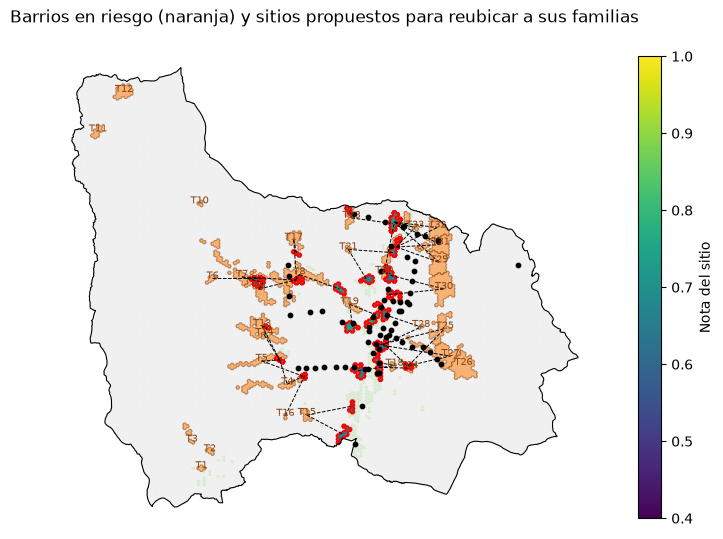

In [23]:
fig, ax = plt.subplots(figsize=(9, 10))
hexes[~eleg].plot(ax=ax, color="#efefef")
hexes[eleg].plot(ax=ax, color="#d9ead3")
territorios.plot(ax=ax, color="tab:orange", alpha=0.55, edgecolor="saddlebrown", lw=0.8)
for tid, t in territorios.iterrows():
    p = t.geometry.representative_point(); ax.annotate(f"T{tid}", (p.x, p.y), fontsize=7, ha="center", color="saddlebrown")
if len(sitios):
    lineas = [LineString([territorios.loc[s["tid"]].geometry.representative_point(), s.geometry.representative_point()])
              for _, s in sitios.iterrows()]
    gpd.GeoSeries(lineas, crs=CRS_PROY).plot(ax=ax, color="k", lw=0.7, linestyle="--")
    sitios.plot(ax=ax, column="nota", cmap="viridis", vmin=0.4, vmax=1, legend=True,
                legend_kwds={"label": "Nota del sitio", "shrink": 0.6}, edgecolor="red", lw=1.5)
DESTINOS["t_masivo"].to_crs(CRS_PROY).clip(limite_p).plot(ax=ax, color="k", markersize=10)
limite_p.boundary.plot(ax=ax, color="k", lw=0.8)
tit = "Barrios en riesgo (naranja) y sitios propuestos para reubicar a sus familias"
if MODO_DEMO: tit += "\nMODO DEMOSTRACIÓN"
if not POT_COMPLETO: tit += "\nPROVISIONAL: faltan mapas de amenaza"
ax.set_title(tit); ax.set_axis_off()
fig.savefig(DIR_SALIDA / "mapa_barrios_y_sitios.png", dpi=200, bbox_inches="tight")

In [24]:
gpkg = DIR_SALIDA / "ciudad_incremental_transporte.gpkg"
cols_hex = ["area_ha", "vulnerable", "tid", "elegible", "motivo_descarte", "frac_amenaza", "dist_a_red",
            "pendiente_media", "sin_acceso_masivo", "costo_obras", "beneficio_ha",
            "c1_conectabilidad", "c4_beneficio", "c5_pendiente"] + COLS_T
hx = hexes[cols_hex + ["geometry"]].copy()
for c in ["vulnerable", "elegible", "sin_acceso_masivo"]:
    hx[c] = hx[c].astype(bool)
hx.reset_index().to_file(gpkg, layer="hexagonos", driver="GPKG")
territorios.reset_index().to_file(gpkg, layer="barrios_en_riesgo", driver="GPKG")
if len(sitios):
    sitios.reset_index().to_file(gpkg, layer="sitios", driver="GPKG")
    sitios.drop(columns="geometry").round(2).to_csv(DIR_SALIDA / "sitios_por_barrio.csv", encoding="utf-8-sig")
    try:
        m = territorios.reset_index().explore(color="orange", name="Barrios en riesgo", tiles="CartoDB positron",
                                              tooltip=["tid", "area_ha", "hoy_t_masivo", "hoy_t_paradero"])
        sitios.reset_index().explore(m=m, column="nota", cmap="viridis", name="Sitios",
                                     tooltip=["sitio", "area_ha", "nota", "dist_barrio_m", "obras", "beneficio_vecinos"])
        m.save(DIR_SALIDA / "mapa_barrios_y_sitios.html")
    except Exception as e:
        print("No se pudo crear el mapa interactivo:", e)
for f in sorted(DIR_SALIDA.iterdir()):
    print("  ", f.name)

   ciudad_incremental_transporte.gpkg
   mapa_barrios_y_sitios.html
   mapa_barrios_y_sitios.png
   red_y_destinos.gpkg
   sitios_por_barrio.csv


## Paso 13 · ¿El resultado depende de cómo se repartieron los puntos?

Los pesos de los criterios (30 %, 20 %, 20 %, 20 %, 10 %) los decidimos nosotros. ¿Y si alguien piensa que la cercanía debería pesar más? Para comprobarlo, se repite la calificación **500 veces con pesos un poco distintos** cada vez y se cuenta en cuántas de esas repeticiones cada sitio sigue siendo bueno:

- **80 % o más:** el sitio es sólido; sale bien casi con cualquier reparto razonable.
- **Menos de 50 %:** el sitio depende mucho de los pesos elegidos; conviene discutirlo antes de recomendarlo.

In [25]:
rng = np.random.default_rng(42)
claves = list(PESOS)
w0 = np.array([PESOS[k] for k in claves]); w0 = w0 / w0.sum()
W = rng.dirichlet(w0 * 30, size=500)       # 500 repartos de pesos parecidos a los elegidos
if len(sitios):
    tabla = pares.set_index(["tid", "hex_id"])[claves]
    solidez = {}
    for sid, s in sitios.iterrows():
        hs = hex_sitio.loc[hex_sitio["sitio"] == sid, "hex_id"].values
        S = tabla.loc[[(s["tid"], h) for h in hs]].values
        solidez[sid] = float(((S @ W.T).mean(axis=0) >= s["umbral"]).mean())
    sitios["solidez"] = pd.Series(solidez)
    print(sitios[["tid", "area_ha", "nota", "solidez"]].round(2).to_string())

        tid  area_ha  nota  solidez
sitio                              
T4-S1     4     7.79  0.76     0.99
T4-S2     4     7.79  0.74     1.00
T5-S1     5     7.79  0.81     1.00
T5-S2     5     7.79  0.68     0.90
T6-S1     6     5.20  0.58     0.69
T7-S1     7    25.98  0.69     0.91
T7-S2     7     7.79  0.62     0.63
T8-S1     8    15.59  0.79     1.00
T8-S2     8    23.38  0.69     0.92
T9-S1     9    25.98  0.67     0.85
T9-S2     9    15.59  0.77     1.00
T13-S1   13     5.20  0.86     1.00
T13-S2   13     7.79  0.70     0.97
T14-S1   14     7.79  0.77     1.00
T14-S2   14     5.20  0.86     1.00
T15-S1   15    31.18  0.64     0.73
T15-S2   15    12.99  0.61     0.55
T16-S1   16     5.20  0.60     0.62
T17-S1   17    12.99  0.70     0.99
T17-S2   17     7.79  0.80     1.00
T18-S1   18    20.78  0.77     0.99
T18-S2   18    36.37  0.65     0.79
T19-S1   19    38.97  0.75     0.98
T19-S2   19    28.58  0.75     0.97
T20-S1   20    33.77  0.77     0.99
T20-S2   20    38.97  0.73  

## Para tener en cuenta al leer los resultados

**Un sitio propuesto** es un terreno seguro, donde el POT permite vivienda, cerca del barrio de origen, y que con las obras de su ficha deja a las familias bien conectadas desde el primer día.

**Un barrio sin sitio** también es un resultado: significa que no hay terreno seguro cerca, y que hay que pensar en otra solución.

**Limitaciones:**
1. **Los mapas son del POT de 2014.** La revisión aprobada en 2026 trae mapas de amenaza nuevos; cuando se publiquen, hay que actualizar.
2. **OpenStreetMap no es perfecto:** en las laderas faltan escaleras y caminos. Hay que revisar los sitios en campo.
3. **Cercanía no es lo mismo que buen servicio:** un paradero cerca con un bus cada hora no es buen acceso. La frecuencia de los buses no está incluida.
4. **Los costos son relativos:** sirven para comparar, no son un presupuesto.
5. **Los pesos y umbrales son una propuesta** para discutir con el equipo.